# 1. Image Processing

In [1]:
from pathlib import Path
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

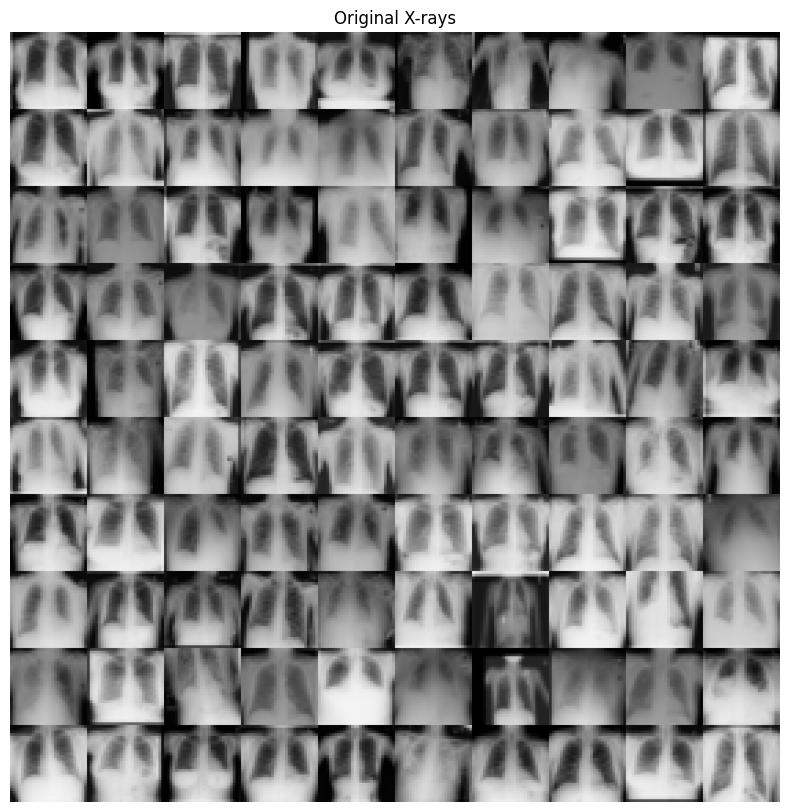

In [11]:
image_path = Path("medmnist_xray_grid.png")
image = Image.open(image_path).convert("L")

pixels = np.asarray(image)
height, width = pixels.shape

plt.figure(figsize=(10, 10))
plt.imshow(pixels, cmap="gray", vmin=0, vmax=255)
plt.axis("off")
plt.title("Original X-rays")
plt.show()

In [4]:
rows, cols = 10, 10
cell_h = height // rows
cell_w = width // cols

xrays = np.stack([
    pixels[r * cell_h:(r + 1) * cell_h, c * cell_w:(c + 1) * cell_w] for r in range(rows) for c in range(cols)
])
xrays.shape

(100, 112, 112)

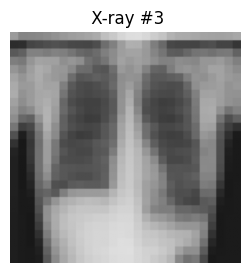

In [8]:
plt.figure(figsize=(3, 3))
plt.imshow(xrays[2], cmap="gray", vmin=0, vmax=255)
plt.axis("off")
plt.title("X-ray #3")
plt.show()

In [9]:
flipped_xrays = np.flip(xrays, axis=2).copy()
flipped_xrays.shape

(100, 112, 112)

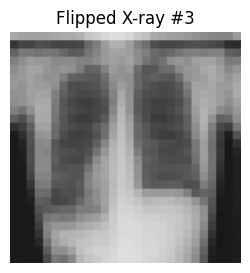

In [13]:
plt.figure(figsize=(3, 3))
plt.imshow(flipped_xrays[2], cmap="gray", vmin=0, vmax=255)
plt.axis("off")
plt.title("Flipped X-ray #3")
plt.show()

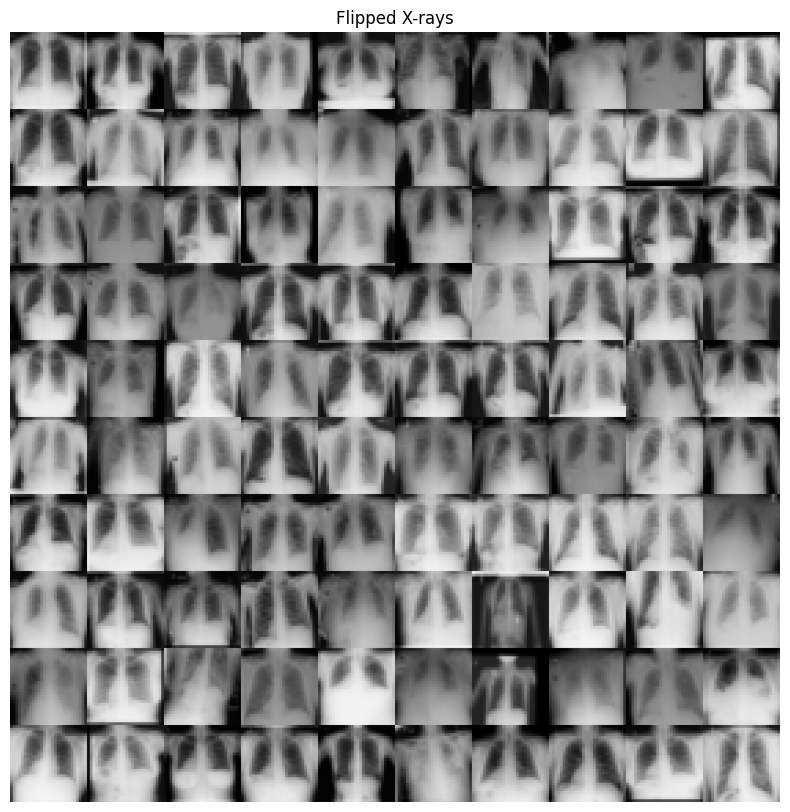

In [12]:
mosaic = np.block([
    [flipped_xrays[r * cols + c] for c in range(cols)] for r in range(rows)
])

plt.figure(figsize=(10, 10))
plt.imshow(mosaic, cmap="gray", vmin=0, vmax=255)
plt.axis("off")
plt.title("Flipped X-rays")
plt.show()

# 2. Text Processing

In [15]:
from pathlib import Path
import re
import nltk
import pandas as pd
import matplotlib.pyplot as plt
from nltk.sentiment import SentimentIntensityAnalyzer

nltk.download("vader_lexicon", quiet=True)

True

In [44]:
book_path = Path("pg1260.txt")
book = book_path.read_text(encoding="utf-8-sig")

book[6330:7500]

'\nCHAPTER I\n\n\nThere was no possibility of taking a walk that day. We had been\nwandering, indeed, in the leafless shrubbery an hour in the morning;\nbut since dinner (Mrs. Reed, when there was no company, dined early)\nthe cold winter wind had brought with it clouds so sombre, and a rain\nso penetrating, that further outdoor exercise was now out of the\nquestion.\n\nI was glad of it: I never liked long walks, especially on chilly\nafternoons: dreadful to me was the coming home in the raw twilight,\nwith nipped fingers and toes, and a heart saddened by the chidings of\nBessie, the nurse, and humbled by the consciousness of my physical\ninferiority to Eliza, John, and Georgiana Reed.\n\nThe said Eliza, John, and Georgiana were now clustered round their mama\nin the drawing-room: she lay reclined on a sofa by the fireside, and\nwith her darlings about her (for the time neither quarrelling nor\ncrying) looked perfectly happy. Me, she had dispensed from joining the\ngroup; saying, “She 

In [17]:
start = re.search(r"\*\*\* START OF THE PROJECT GUTENBERG EBOOK[^\n]*\*\*\*", book)
end = re.search(r"\*\*\* END OF THE PROJECT GUTENBERG EBOOK[^\n]*\*\*\*", book)

book = book[start.end():end.start()]
len(book)

1022385

In [18]:
chapter_pattern = re.compile(r"(?m)^CHAPTER\s+([IVXLCDM]+)(?:[—–-]CONCLUSION)?\s*$")
matches = list(chapter_pattern.finditer(book))
chapters = [
    book[m.end():matches[i + 1].start() if i + 1 < len(matches) else len(book)].strip() for i, m in enumerate(matches)
]

len(chapters)

38

In [30]:
chapters[0][:100]

'There was no possibility of taking a walk that day. We had been\nwandering, indeed, in the leafless s'

In [21]:
analyzer = SentimentIntensityAnalyzer()
records = []
for chapter_number, chapter_text in enumerate(chapters, start=1):
    paragraphs = [p.replace("\n", " ").strip() for p in re.split(r"\n\s*\n", chapter_text) if p.strip()]
    scores = [analyzer.polarity_scores(p)["compound"] for p in paragraphs]
    records.append({
        "chapter": chapter_number,
        "sentiment": sum(scores) / len(scores),
        "paragraphs": len(paragraphs),
        "words": len(chapter_text.split()),
    })

df = pd.DataFrame(records)
df

,chapter,sentiment,paragraphs,words
0,1,-0.090457,42,1927
1,2,-0.311666,44,2734
2,3,0.007689,89,3189
3,4,0.013983,124,5798
4,5,0.068439,114,4986
5,6,-0.071296,67,2902
6,7,-0.077700,56,3574
7,8,0.035281,62,2988
8,9,0.113033,61,3240
9,10,0.202386,85,4352


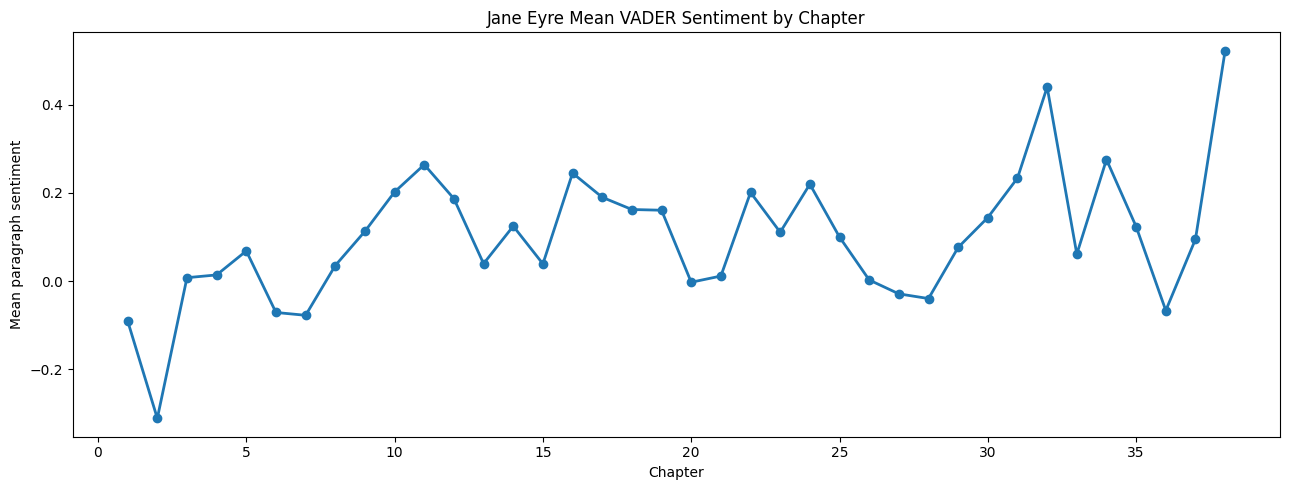

In [27]:
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(df["chapter"], df["sentiment"], marker="o", linewidth=2)
ax.set(
    title="Jane Eyre Mean VADER Sentiment by Chapter",
    xlabel="Chapter",
    ylabel="Mean paragraph sentiment",
)
plt.tight_layout()
plt.show()